# Lab Sheet 05

Harsh Saini | Roll 253028036

MCA III Semester, Session 2026-2027

Run all cells in order from this folder. Outputs below are captured from execution, not typed examples. See README for dataset sources.

## Common setup
Run once before Program 1.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Run this file or notebook from the practicals folder.
DATA = Path("datasets")
OUT = Path("outputs") / "lab_05"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 78)
pd.set_option("display.max_columns", 8)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
np.set_printoptions(precision=3, suppress=True)
sns.set_theme(style="whitegrid", font_scale=0.9)

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=160)
    plt.show()

import gymnasium as gym
from gymnasium import spaces
import torch
from torch import nn
from collections import deque
import random
import time

torch.set_num_threads(1)
# CPU runs with fixed seeds; timing and minor results may vary.
SEED = 42


## Program 01: Install and configure the Gymnasium (or OpenAI Gym) library.

**Procedure:** Install Gymnasium, create FrozenLake-v1, and reset with a seed.

In [2]:
print("Gymnasium version:", gym.__version__)
print("Install command: python -m pip install gymnasium")
env = gym.make("FrozenLake-v1", is_slippery=False,
               render_mode="ansi")
state, info = env.reset(seed=SEED)
print("FrozenLake created; start state:", state)


Gymnasium version: 1.4.0
Install command: python -m pip install gymnasium
FrozenLake created; start state: 0


**Observation:** This practical uses non-slippery FrozenLake so the first tabular example is easier to reproduce.

## Program 02: Create and execute a simple Reinforcement Learning environment.

**Procedure:** Reset, render the map, and execute one action.

In [3]:
state, info = env.reset(seed=SEED)
print("Initial state:", state)
print(env.render())
next_state, reward, terminated, truncated, info = env.step(2)
print("After moving right:", next_state)
print("Reward:", reward)
print("Terminated:", terminated, "Truncated:", truncated)


Initial state: 0

SFFF
FHFH
FFFH
HFFG

After moving right: 1
Reward: 0
Terminated: False Truncated: False


**Observation:** A step returns the next observation, reward, two ending flags, and extra information.

## Program 03: Explore the observation space and action space of an RL environment.

**Procedure:** Inspect observation_space and action_space.

In [4]:
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Number of states:", env.observation_space.n)
print("Number of actions:", env.action_space.n)
print("Actions: 0=left, 1=down, 2=right, 3=up")


Observation space: Discrete(16)
Action space: Discrete(4)
Number of states: 16
Number of actions: 4
Actions: 0=left, 1=down, 2=right, 3=up


**Observation:** FrozenLake has 16 discrete states and four possible actions.

## Program 04: Display the states, actions, rewards, and termination conditions of an environment.

**Procedure:** Display the state map, action meanings, rewards, and stopping rules.

In [5]:
print("State IDs:\n", np.arange(16).reshape(4, 4))
print("Map:\n", env.unwrapped.desc.astype("U1"))
print("S=start, F=frozen, H=hole, G=goal")
print("Reward: 1 at goal; otherwise 0.")
print("Termination: goal or hole.")
print("Truncation: the time limit is reached.")


State IDs:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]]
Map:
 [['S' 'F' 'F' 'F']
 ['F' 'H' 'F' 'H']
 ['F' 'F' 'F' 'H']
 ['H' 'F' 'F' 'G']]
S=start, F=frozen, H=hole, G=goal
Reward: 1 at goal; otherwise 0.
Termination: goal or hole.
Truncation: the time limit is reached.


**Observation:** Termination is a task ending; truncation is an external step limit.

## Program 05: Simulate random actions in the FrozenLake environment.

**Procedure:** Sample random actions, record transitions, and stop at the episode ending.

In [6]:
env.action_space.seed(SEED)
state, _ = env.reset(seed=SEED)
trajectory = []
for step in range(20):
    action = env.action_space.sample()
    next_state, reward, terminated, truncated, _ = env.step(action)
    trajectory.append([step + 1, state, action, next_state, reward])
    state = next_state
    if terminated or truncated:
        break
print(pd.DataFrame(trajectory,
    columns=["step", "state", "action", "next_state", "reward"]))


   step  state  action  next_state  reward
0     1      0       0           0       0
1     2      0       3           0       0
2     3      0       2           1       0
3     4      1       1           5       0


**Observation:** Random actions do not use previous experience and can enter a hole.

## Program 06: Implement the Q-Learning algorithm for the FrozenLake environment.

**Procedure:** Initialize a table, choose epsilon-greedy actions, apply the Bellman update, and record rewards.

In [7]:
def train_q(environment, episodes=3000, alpha=0.5,
            gamma=0.95, epsilon=0.8, decay=True, seed=42):
    rng = np.random.default_rng(seed)
    q = np.zeros((environment.observation_space.n,
                  environment.action_space.n))
    rewards = []
    changes = []
    started = time.perf_counter()
    steps = 0
    for episode in range(episodes):
        state, _ = environment.reset(seed=seed + episode)
        total_reward = 0.0
        max_change = 0.0
        explore = (max(0.05, epsilon * (0.997 ** episode))
                   if decay else epsilon)
        while True:
            if rng.random() < explore:
                action = int(rng.integers(environment.action_space.n))
            else:
                best = np.flatnonzero(q[state] == q[state].max())
                action = int(rng.choice(best))
            next_state, reward, terminated, truncated, _ = (
                environment.step(action))
            # A true terminal state has no future value.
            future = 0.0 if terminated else q[next_state].max()
            old_value = q[state, action]
            q[state, action] += alpha * (
                reward + gamma * future - old_value)
            max_change = max(max_change,
                             abs(q[state, action] - old_value))
            state = next_state
            total_reward += reward
            steps += 1
            if terminated or truncated:
                break
        rewards.append(total_reward)
        changes.append(max_change)
    return {"q": q, "rewards": np.array(rewards),
            "changes": np.array(changes), "steps": steps,
            "seconds": time.perf_counter() - started}

def evaluate_q(environment, q, episodes=100, seed=9000):
    rewards = []
    for episode in range(episodes):
        state, _ = environment.reset(seed=seed + episode)
        total_reward = 0.0
        while True:
            action = int(np.argmax(q[state]))
            state, reward, terminated, truncated, _ = environment.step(action)
            total_reward += reward
            if terminated or truncated:
                break
        rewards.append(total_reward)
    return np.array(rewards)

print("Q-learning functions defined.")
print("Q <- Q + alpha * (reward + gamma * max_next_Q - Q)")


Q-learning functions defined.
Q <- Q + alpha * (reward + gamma * max_next_Q - Q)


**Observation:** The bootstrap is disabled at true terminal states. Time-limit truncation ends the rollout but is not treated as a terminal task state.

## Program 07: Initialize and update the Q-table during training.

**Procedure:** Initialize a zero Q-table and apply one terminal transition update.

In [8]:
example_q = np.zeros((16, 4))
state, action, reward, next_state = 14, 2, 1.0, 15
alpha, gamma = 0.5, 0.95
terminal = True
future = 0.0 if terminal else example_q[next_state].max()
example_q[state, action] += alpha * (
    reward + gamma * future - example_q[state, action])
print("Q-table shape:", example_q.shape)
print("Updated Q[14, 2]:", example_q[14, 2])


Q-table shape: (16, 4)
Updated Q[14, 2]: 0.5


**Observation:** The update assigns value 0.5 to an initially zero goal-reaching action.

## Program 08: Train the agent for multiple episodes using Q-Learning.

**Procedure:** Train Q-learning for 3,000 episodes and record reward progress.

In [9]:
frozen = train_q(env, episodes=3000, seed=SEED)
q_table = frozen["q"]
print("Training episodes:", len(frozen["rewards"]))
print("Total environment steps:", frozen["steps"])
print("Goal visits:", int(frozen["rewards"].sum()))
print("Last 100 training mean reward:",
      round(frozen["rewards"][-100:].mean(), 3))


Training episodes: 3000
Total environment steps: 19108
Goal visits: 2596
Last 100 training mean reward: 0.95


**Observation:** Training rewards include exploration, so greedy evaluation can perform differently.

## Program 09: Display the learned Q-table after training.

**Procedure:** Display and save the learned action-value table.

In [10]:
print(pd.DataFrame(q_table,
    columns=["left", "down", "right", "up"]).round(3))
np.save(OUT / "frozenlake_q.npy", q_table)


    left  down  right    up
0  0.735 0.774  0.774 0.735
1  0.735 0.000  0.815 0.774
2  0.774 0.857  0.774 0.815
3  0.815 0.000  0.773 0.468
4  0.761 0.815  0.000 0.551
5  0.000 0.000  0.000 0.000
6  0.000 0.902  0.000 0.815
7  0.000 0.000  0.000 0.000
8  0.583 0.000  0.857 0.386
9  0.808 0.844  0.902 0.000
10 0.857 0.950  0.000 0.857
11 0.000 0.000  0.000 0.000
12 0.000 0.000  0.000 0.000
13 0.000 0.649  0.950 0.803
14 0.902 0.950  1.000 0.902
15 0.000 0.000  0.000 0.000


**Observation:** Terminal goal and hole states have no outgoing learned value.

## Program 10: Evaluate the trained Q-Learning agent.

**Procedure:** Evaluate 100 separate reset seeds using the learned greedy policy.

In [11]:
frozen_eval = evaluate_q(env, q_table)
print("Evaluation episodes:", len(frozen_eval))
print("Success rate:", round(float((frozen_eval > 0).mean()), 3))
print("Mean reward:", round(frozen_eval.mean(), 3))


Evaluation episodes: 100
Success rate: 1.0
Mean reward: 1.0


**Observation:** Evaluation uses greedy actions without epsilon exploration on the same non-slippery map.

## Program 11: Plot the cumulative rewards obtained during training.

**Procedure:** Cumulatively sum training rewards and plot them.

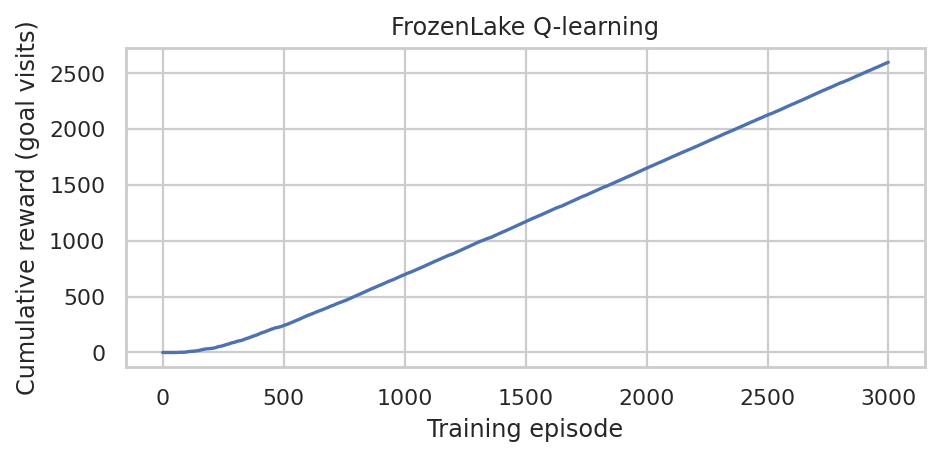

In [12]:
plt.figure(figsize=(6, 3))
plt.plot(np.cumsum(frozen["rewards"]))
plt.xlabel("Training episode")
plt.ylabel("Cumulative reward (goal visits)")
plt.title("FrozenLake Q-learning")
save_plot("11_cumulative_rewards")


**Observation:** An increasing cumulative curve indicates repeated goal visits, but a rolling average is more useful for convergence.

## Program 12: Study the effect of different learning rates on Q-Learning performance.

**Procedure:** Vary only alpha and compare training and greedy evaluation results.

In [13]:
def q_sweep(parameter, values):
    rows = []
    for value in values:
        training_means, evaluation_means = [], []
        for seed in [42, 43, 44]:
            arguments = {parameter: value}
            if parameter == "epsilon":
                arguments["decay"] = False
            result = train_q(env, episodes=1000, seed=seed, **arguments)
            training_means.append(result["rewards"][-100:].mean())
            evaluation_means.append(evaluate_q(env, result["q"]).mean())
        rows.append({parameter: value,
            "train_last100": np.mean(training_means),
            "eval_mean": np.mean(evaluation_means),
            "eval_std": np.std(evaluation_means)})
    return pd.DataFrame(rows)

alpha_results = q_sweep("alpha", [0.1, 0.5, 0.9])
print(alpha_results)


   alpha  train_last100  eval_mean  eval_std
0  0.100          0.943      1.000     0.000
1  0.500          0.910      1.000     0.000
2  0.900          0.917      1.000     0.000


**Observation:** Each setting uses three training seeds and the same episode budget; this simple environment may saturate at perfect success.

## Program 13: Study the effect of different discount factor (Gamma) values.

**Procedure:** Repeat the controlled sweep for three discount factors.

In [14]:
gamma_results = q_sweep("gamma", [0.5, 0.9, 0.99])
print(gamma_results)


   gamma  train_last100  eval_mean  eval_std
0  0.500          0.933      1.000     0.000
1  0.900          0.910      1.000     0.000
2  0.990          0.910      1.000     0.000


**Observation:** Gamma controls how much delayed rewards contribute to current action values.

## Program 14: Compare exploration and exploitation using different epsilon values.

**Procedure:** Use constant epsilon values and compare exploratory training with greedy evaluation.

In [15]:
epsilon_results = q_sweep("epsilon", [0.1, 0.5, 0.9])
print(epsilon_results)


   epsilon  train_last100  eval_mean  eval_std
0    0.100          0.893      1.000     0.000
1    0.500          0.363      1.000     0.000
2    0.900          0.043      1.000     0.000


**Observation:** Constant high epsilon can reduce training rewards even when the learned greedy policy succeeds.

## Program 15: Implement an epsilon-greedy action selection policy.

**Procedure:** Generate actions using a random draw against epsilon.

In [16]:
def epsilon_greedy(q, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(q.shape[1]))
    return int(np.argmax(q[state]))

rng = np.random.default_rng(SEED)
state = 0
print("Greedy action:", int(np.argmax(q_table[state])))
print("Ten epsilon-greedy actions (epsilon=0.3):")
print([epsilon_greedy(q_table, state, 0.3, rng)
       for _ in range(10)])


Greedy action: 2
Ten epsilon-greedy actions (epsilon=0.3):
[2, 2, 2, 2, 2, 2, 2, 3, 2, 2]


**Observation:** The policy sometimes explores and otherwise selects a maximum-value action.

## Program 16: Design a simple Grid World environment.

**Procedure:** Define reset and step methods, then add a 64-step time limit.

In [17]:
class GridWorld(gym.Env):
    def __init__(self):
        super().__init__()
        self.observation_space = spaces.Discrete(16)
        self.action_space = spaces.Discrete(4)
        self.walls = {5, 7, 11}
        self.goal = 15
        self.state = 0

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.state = 0
        return self.state, {}

    def step(self, action):
        if not self.action_space.contains(action):
            raise ValueError("Action must be 0, 1, 2 or 3")
        if self.state == self.goal:
            raise RuntimeError("Reset after reaching the goal")
        row, column = divmod(self.state, 4)
        movement = [(0, -1), (1, 0), (0, 1), (-1, 0)]
        dr, dc = movement[action]
        new_row = int(np.clip(row + dr, 0, 3))
        new_column = int(np.clip(column + dc, 0, 3))
        candidate = new_row * 4 + new_column
        if candidate not in self.walls:
            self.state = candidate
        terminated = self.state == self.goal
        reward = 1.0 if terminated else -0.01
        return self.state, reward, terminated, False, {}

grid = gym.wrappers.TimeLimit(GridWorld(), max_episode_steps=64)
print("Grid:", grid.observation_space, grid.action_space)
print("Walls:", sorted(grid.unwrapped.walls))
print("Start:", grid.reset(seed=SEED)[0], "Goal:", grid.unwrapped.goal)


Grid: Discrete(16) Discrete(4)
Walls: [5, 7, 11]
Start: 0 Goal: 15


**Observation:** The custom 4x4 world uses walls, a small step penalty, and a reward at the goal.

## Program 17: Train a Q-Learning agent in the custom Grid World.

**Procedure:** Train a Q-learning table in the custom Grid World and evaluate it.

In [18]:
grid_result = train_q(grid, episodes=2000, seed=SEED)
grid_eval = evaluate_q(grid, grid_result["q"])
print("Training episodes:", len(grid_result["rewards"]))
print("Evaluation mean reward:", round(grid_eval.mean(), 3))
print("Successful episodes:", int((grid_eval > 0).sum()))
np.save(OUT / "gridworld_q.npy", grid_result["q"])


Training episodes: 2000
Evaluation mean reward: 0.95
Successful episodes: 100


**Observation:** The step penalty encourages a shorter route among goal-reaching routes.

## Program 18: Visualize the optimal path learned by the agent.

**Procedure:** Follow greedy actions, record visited cells, calculate the shortest valid route, and draw the path.

Greedy learned path: [0, 4, 8, 12, 13, 14, 15]
Path length: 6
Reached goal: True
Shortest possible steps: 6


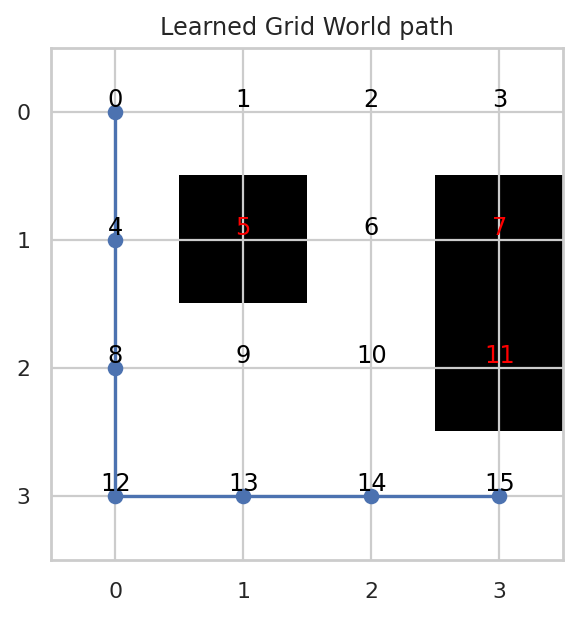

In [19]:
state, _ = grid.reset(seed=10000)
path = [state]
for _ in range(64):
    action = int(np.argmax(grid_result["q"][state]))
    state, reward, terminated, truncated, _ = grid.step(action)
    path.append(state)
    if terminated or truncated:
        break
print("Greedy learned path:", path)
print("Path length:", len(path) - 1)
print("Reached goal:", state == grid.unwrapped.goal)
# Verify against shortest-path length using breadth-first search.
queue = deque([(0, 0)])
visited = {0}
shortest = None
while queue:
    node, distance = queue.popleft()
    if node == 15:
        shortest = distance
        break
    row, column = divmod(node, 4)
    for dr, dc in [(0, -1), (1, 0), (0, 1), (-1, 0)]:
        r, c = row + dr, column + dc
        nxt = r * 4 + c
        if (0 <= r < 4 and 0 <= c < 4 and
                nxt not in visited and nxt not in grid.unwrapped.walls):
            visited.add(nxt)
            queue.append((nxt, distance + 1))
print("Shortest possible steps:", shortest)
plt.figure(figsize=(4, 4))
board = np.zeros((4, 4))
for wall in grid.unwrapped.walls:
    board[wall // 4, wall % 4] = 1
plt.imshow(board, cmap="Greys", vmin=0, vmax=1)
plt.plot([s % 4 for s in path], [s // 4 for s in path], "o-")
for s in range(16):
    plt.text(s % 4, s // 4, str(s), ha="center", va="bottom",
             color="red" if s in grid.unwrapped.walls else "black")
plt.xticks(range(4))
plt.yticks(range(4))
plt.title("Learned Grid World path")
save_plot("18_grid_path")


**Observation:** The learned route is checked against a breadth-first shortest-path calculation before calling it optimal.

## Program 19: Compare agent performance in FrozenLake and Grid World environments.

**Procedure:** Compare environment sizes and evaluation results with the reward difference stated.

In [20]:
print(pd.DataFrame({
    "environment": ["FrozenLake (non-slippery)", "Grid World"],
    "states": [16, 16],
    "actions": [4, 4],
    "success_rate": [(frozen_eval > 0).mean(),
                     (grid_eval > 0).mean()],
    "mean_return": [frozen_eval.mean(), grid_eval.mean()]}))
print("Reward rules differ; mean returns are not a fair ranking.")


                 environment  states  actions  success_rate  mean_return
0  FrozenLake (non-slippery)      16        4         1.000        1.000
1                 Grid World      16        4         1.000        0.950
Reward rules differ; mean returns are not a fair ranking.


**Observation:** Success rates describe reaching each environment goal; mean returns use different reward rules.

## Program 20: Analyze the convergence behavior of the Q-Learning algorithm.

**Procedure:** Plot rolling rewards and the largest update recorded in each episode.

Final 100-episode mean maximum Q update: 0.0


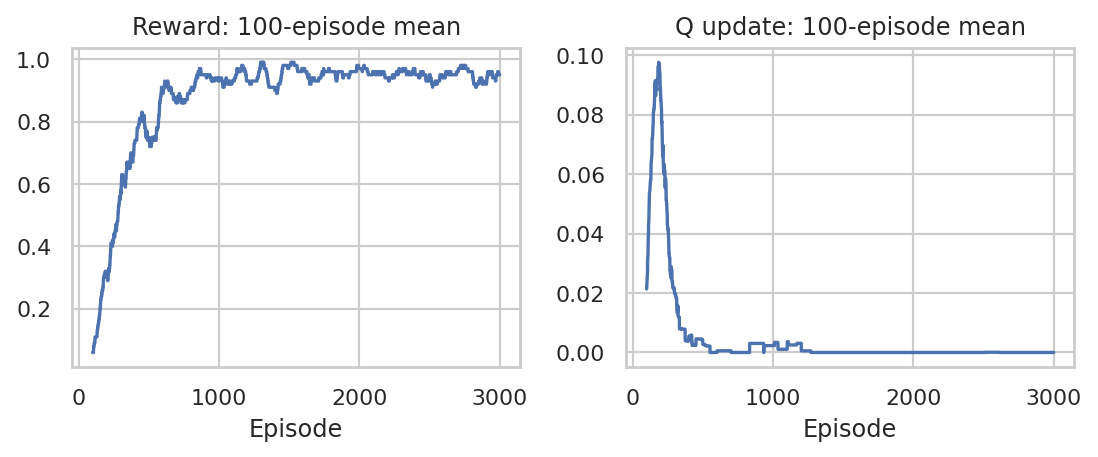

In [21]:
reward_average = pd.Series(frozen["rewards"]).rolling(100).mean()
change_average = pd.Series(frozen["changes"]).rolling(100).mean()
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].plot(reward_average)
axes[0].set_title("Reward: 100-episode mean")
axes[0].set_xlabel("Episode")
axes[1].plot(change_average)
axes[1].set_title("Q update: 100-episode mean")
axes[1].set_xlabel("Episode")
save_plot("20_q_convergence")
print("Final 100-episode mean maximum Q update:",
      round(frozen["changes"][-100:].mean(), 6))


**Observation:** Stabilizing rewards and shrinking updates suggest learning has settled in this finite example; they are not a general proof of convergence.

## Program 21: Install the required libraries for Deep Q-Network implementation.

**Procedure:** Install the DQN dependencies, import PyTorch, and create a tensor.

In [22]:
print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Device: CPU")
print("Install: python -m pip install torch gymnasium matplotlib")
print("Tensor:", torch.tensor([1.0, 2.0, 3.0]))


PyTorch version: 2.14.1+cpu
NumPy version: 2.3.5
Device: CPU
Install: python -m pip install torch gymnasium matplotlib
Tensor: tensor([1., 2., 3.])


**Observation:** The DQN uses PyTorch on the CPU and does not require a GPU.

## Program 22: Implement a basic Deep Q-Network using TensorFlow or PyTorch.

**Procedure:** Define a neural Q-network, epsilon-greedy training, replay sampling, Bellman targets, and greedy evaluation.

In [23]:
class DQN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(4, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))

    def forward(self, state):
        return self.layers(state)

def evaluate_dqn(model, episodes=20, seed=10000):
    environment = gym.make("CartPole-v1")
    scores = []
    model.eval()
    with torch.no_grad():
        for episode in range(episodes):
            state, _ = environment.reset(seed=seed + episode)
            total = 0.0
            while True:
                values = model(torch.tensor(state, dtype=torch.float32))
                action = int(values.argmax().item())
                state, reward, terminated, truncated, _ = environment.step(action)
                total += reward
                if terminated or truncated:
                    break
            scores.append(total)
    environment.close()
    return np.array(scores)

def train_dqn(episodes=250, seed=42, replay=True,
              use_target=True, learning_rate=0.001):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    environment = gym.make("CartPole-v1")
    online, target = DQN(), DQN()
    target.load_state_dict(online.state_dict())
    target.eval()
    optimizer = torch.optim.Adam(online.parameters(), lr=learning_rate)
    loss_function = nn.SmoothL1Loss()
    memory = deque(maxlen=10000)
    rewards = []
    steps = 0
    epsilon = 1.0
    gamma = 0.99
    batch_size = 64
    started = time.perf_counter()
    for episode in range(episodes):
        state, _ = environment.reset(seed=seed + episode)
        total = 0.0
        while True:
            if random.random() < epsilon:
                action = random.randrange(2)
            else:
                with torch.no_grad():
                    values = online(torch.tensor(state, dtype=torch.float32))
                    action = int(values.argmax().item())
            next_state, reward, terminated, truncated, _ = environment.step(action)
            # Bootstrap at time-limit truncation, not true termination.
            transition = (state.copy(), action, reward,
                          next_state.copy(), float(terminated))
            memory.append(transition)
            steps += 1
            # Same update frequency and optimizer for all ablations.
            ready = len(memory) >= batch_size if replay else True
            if ready and steps % 4 == 0:
                batch = (random.sample(memory, batch_size) if replay
                         else [transition])
                states, actions, values, next_states, terminals = zip(*batch)
                states = torch.tensor(np.array(states), dtype=torch.float32)
                actions = torch.tensor(actions, dtype=torch.long).unsqueeze(1)
                values = torch.tensor(values, dtype=torch.float32)
                next_states = torch.tensor(np.array(next_states), dtype=torch.float32)
                terminals = torch.tensor(terminals, dtype=torch.float32)
                predicted = online(states).gather(1, actions).squeeze(1)
                with torch.no_grad():
                    network = target if use_target else online
                    future = network(next_states).max(dim=1).values
                    expected = values + gamma * (1 - terminals) * future
                loss = loss_function(predicted, expected)
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(online.parameters(), max_norm=10.0)
                optimizer.step()
            if use_target and steps % 250 == 0:
                target.load_state_dict(online.state_dict())
            state = next_state
            total += reward
            if terminated or truncated:
                break
        rewards.append(total)
        epsilon = max(0.05, epsilon * 0.98)
    environment.close()
    return {"model": online, "rewards": np.array(rewards),
            "seconds": time.perf_counter() - started, "steps": steps,
            "seed": seed, "learning_rate": learning_rate}

print(DQN())
print("Inputs: four CartPole observations; outputs: two Q-values.")
print("Replay capacity: 10000; batch: 64; gamma: 0.99.")


DQN(
  (layers): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)
Inputs: four CartPole observations; outputs: two Q-values.
Replay capacity: 10000; batch: 64; gamma: 0.99.


**Observation:** The online network learns Q-values. A replay buffer and periodically copied target network stabilize the update; they are tested later with controlled ablations.

## Program 23: Train a DQN agent on the CartPole environment.

**Procedure:** Train the DQN on CartPole-v1 and compare early and late training returns.

In [24]:
dqn_result = train_dqn(episodes=250, seed=SEED)
print("Training episodes:", len(dqn_result["rewards"]))
print("Environment steps:", dqn_result["steps"])
print("First 20 mean reward:", dqn_result["rewards"][:20].mean())
print("Last 20 mean reward:", dqn_result["rewards"][-20:].mean())


Training episodes: 250
Environment steps: 14644
First 20 mean reward: 18.15
Last 20 mean reward: 103.9


**Observation:** A fixed 250-episode CPU run is recorded honestly; it is not assumed to solve CartPole.

## Program 24: Plot the episode-wise reward obtained during DQN training.

**Procedure:** Plot episode-wise DQN rewards and their 20-episode rolling mean.

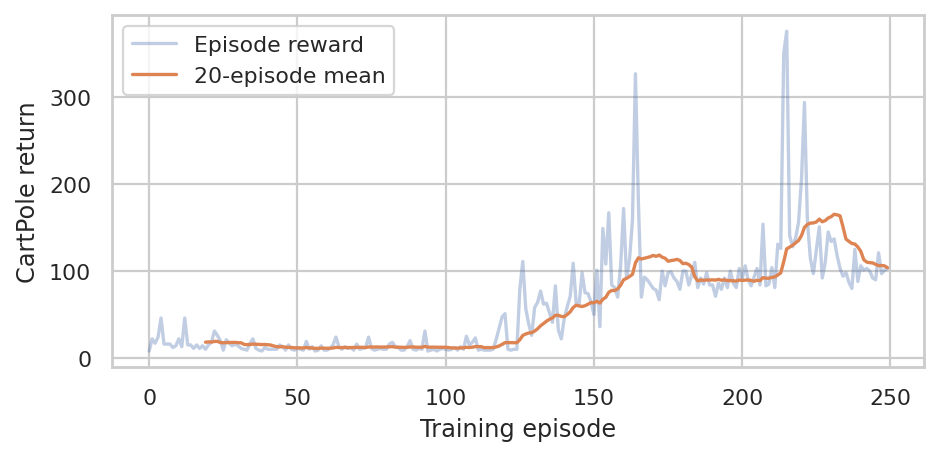

In [25]:
plt.figure(figsize=(6, 3))
plt.plot(dqn_result["rewards"], alpha=0.35, label="Episode reward")
plt.plot(pd.Series(dqn_result["rewards"]).rolling(20).mean(),
         label="20-episode mean")
plt.xlabel("Training episode")
plt.ylabel("CartPole return")
plt.legend()
save_plot("24_dqn_rewards")


**Observation:** Training returns include exploratory actions. The moving average reduces visual noise.

## Program 25: Evaluate the trained DQN agent.

**Procedure:** Run a greedy DQN policy in 20 evaluation episodes.

In [26]:
dqn_eval = evaluate_dqn(dqn_result["model"], episodes=20)
print("Greedy evaluation episodes:", len(dqn_eval))
print("Mean return:", round(dqn_eval.mean(), 3))
print("Standard deviation:", round(dqn_eval.std(), 3))
print("Minimum / maximum:", dqn_eval.min(), dqn_eval.max())
print("500-step episodes:", int((dqn_eval == 500).sum()))


Greedy evaluation episodes: 20
Mean return: 107.0
Standard deviation: 11.353
Minimum / maximum: 89.0 141.0
500-step episodes: 0


**Observation:** These are 20 new reset seeds without training exploration; the maximum CartPole-v1 episode length is 500.

## Program 26: Compare Q-Learning and DQN performance.

**Procedure:** Discretize CartPole states, train a tabular agent for 250 episodes, and evaluate both agents on matching seeds.

In [27]:
# A binned Q-table provides a same-environment comparison.
bins = [np.linspace(-2.4, 2.4, 7), np.linspace(-3, 3, 7),
        np.linspace(-0.21, 0.21, 9), np.linspace(-3, 3, 7)]
shape = tuple(len(edges) + 1 for edges in bins) + (2,)

def discretize(state):
    return tuple(int(np.digitize(value, edges))
                 for value, edges in zip(state, bins))

cart_env = gym.make("CartPole-v1")
cart_q = np.zeros(shape)
rng = np.random.default_rng(SEED)
cart_rewards = []
cart_steps = 0
started = time.perf_counter()
for episode in range(250):
    state, _ = cart_env.reset(seed=SEED + episode)
    epsilon = max(0.05, 0.98 ** episode)
    total = 0.0
    while True:
        key = discretize(state)
        action = (int(rng.integers(2)) if rng.random() < epsilon
                  else int(np.argmax(cart_q[key])))
        nxt, reward, terminated, truncated, _ = cart_env.step(action)
        future = 0 if terminated else cart_q[discretize(nxt)].max()
        cart_q[key + (action,)] += 0.2 * (
            reward + 0.99 * future - cart_q[key + (action,)])
        state = nxt
        total += reward
        cart_steps += 1
        if terminated or truncated:
            break
    cart_rewards.append(total)
cart_seconds = time.perf_counter() - started
cart_eval = []
for episode in range(20):
    state, _ = cart_env.reset(seed=10000 + episode)
    total = 0
    while True:
        action = int(np.argmax(cart_q[discretize(state)]))
        state, reward, terminated, truncated, _ = cart_env.step(action)
        total += reward
        if terminated or truncated:
            break
    cart_eval.append(total)
cart_env.close()
cart_eval = np.array(cart_eval)
print(pd.DataFrame({
    "algorithm": ["Binned Q-learning", "DQN"],
    "training_episodes": [250, 250],
    "environment_steps": [cart_steps, dqn_result["steps"]],
    "evaluation_mean": [cart_eval.mean(), dqn_eval.mean()],
    "evaluation_std": [cart_eval.std(), dqn_eval.std()]}))


           algorithm  training_episodes  environment_steps  evaluation_mean  \
0  Binned Q-learning                250              16769          114.800   
1                DQN                250              14644          107.000   

   evaluation_std  
0          42.843  
1          11.353  


**Observation:** Both use CartPole and the same evaluation seeds, but have different representations and step counts. One training seed is a demonstration, not a reliable algorithm ranking.

## Program 27: Analyze the effect of replay memory on DQN performance.

**Procedure:** Compare replay with a current-transition update while keeping the episode budget, optimizer, and other settings fixed.

In [28]:
# Two seeds per setting, same 250-episode training budget.
ablations = []
for name, replay, target_network in [
        ("Replay + target", True, True),
        ("No replay", False, True),
        ("No target", True, False)]:
    for seed in [42, 43]:
        run = train_dqn(episodes=250, seed=seed, replay=replay,
                        use_target=target_network)
        scores = evaluate_dqn(run["model"])
        ablations.append({"setting": name, "seed": seed,
                          "eval_mean": scores.mean(),
                          "last20_train": run["rewards"][-20:].mean(),
                          "steps": run["steps"]})
ablation_table = pd.DataFrame(ablations)
print(ablation_table.loc[
    ablation_table["setting"].isin(["Replay + target", "No replay"])])


           setting  seed  eval_mean  last20_train  steps
0  Replay + target    42    107.000       103.900  14644
1  Replay + target    43      9.450        12.700   4869
2        No replay    42      9.450         9.500   2999
3        No replay    43      9.400         9.900   2794


**Observation:** No-replay updates use only the current transition, so this removes both historical sampling and batch averaging. Two seeds provide only preliminary evidence.

## Program 28: Study the role of the target network in DQN.

**Procedure:** Compare target-network and online-only bootstrap runs from the controlled experiment.

In [29]:
print(ablation_table.loc[
    ablation_table["setting"].isin(["Replay + target", "No target"])])
print("Target network: frozen bootstrap estimates between copies.")
print("No target: bootstrap with the current online network.")


           setting  seed  eval_mean  last20_train  steps
0  Replay + target    42    107.000       103.900  14644
1  Replay + target    43      9.450        12.700   4869
4        No target    42      9.400         9.850   2740
5        No target    43      9.400         9.650   2828
Target network: frozen bootstrap estimates between copies.
No target: bootstrap with the current online network.


**Observation:** The target-network experiment uses the same replay setting and training budget. Measured returns can vary considerably with seed.

## Program 29: Save the trained DQN model.

**Procedure:** Save the learned PyTorch state_dict and metadata.

In [30]:
torch.save({"state_dict": dqn_result["model"].state_dict(),
            "seed": SEED, "episodes": 250}, OUT / "cartpole_dqn.pt")
print("Saved: cartpole_dqn.pt")
print("Architecture: 4 -> 64 -> 64 -> 2")


Saved: cartpole_dqn.pt
Architecture: 4 -> 64 -> 64 -> 2


**Observation:** The checkpoint stores network parameters and simple training metadata.

## Program 30: Load the saved DQN model and perform testing.

**Procedure:** Load the checkpoint safely and repeat the greedy evaluation.

In [31]:
checkpoint = torch.load(OUT / "cartpole_dqn.pt",
                        map_location="cpu", weights_only=True)
loaded_dqn = DQN()
loaded_dqn.load_state_dict(checkpoint["state_dict"])
loaded_scores = evaluate_dqn(loaded_dqn)
print("Reloaded evaluation mean:", loaded_scores.mean())
print("Matches original evaluation:",
      np.array_equal(loaded_scores, dqn_eval))


Reloaded evaluation mean: 107.0
Matches original evaluation: True


**Observation:** The loaded network produces the same evaluation returns with the same reset seeds.

## Program 31: Compare cumulative rewards obtained using different RL algorithms.

**Procedure:** Compare cumulative training returns on the same CartPole task.

CartPole total training rewards:
Binned Q-learning: 16769.0
DQN: 14644.0


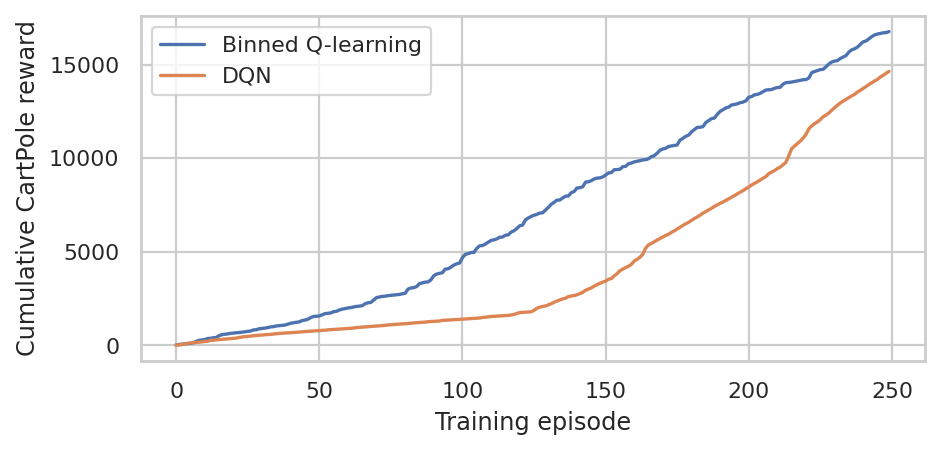

In [32]:
print("CartPole total training rewards:")
print("Binned Q-learning:", np.sum(cart_rewards))
print("DQN:", dqn_result["rewards"].sum())
plt.figure(figsize=(6, 3))
plt.plot(np.cumsum(cart_rewards), label="Binned Q-learning")
plt.plot(np.cumsum(dqn_result["rewards"]), label="DQN")
plt.xlabel("Training episode")
plt.ylabel("Cumulative CartPole reward")
plt.legend()
save_plot("31_algorithm_cumulative")


**Observation:** Cumulative reward depends on episode lengths and exploration; evaluation scores provide a separate view of learned policy quality.

## Program 32: Visualize the learning curve of the RL agent.

**Procedure:** Plot the learning curves separately with clearly labelled environments.

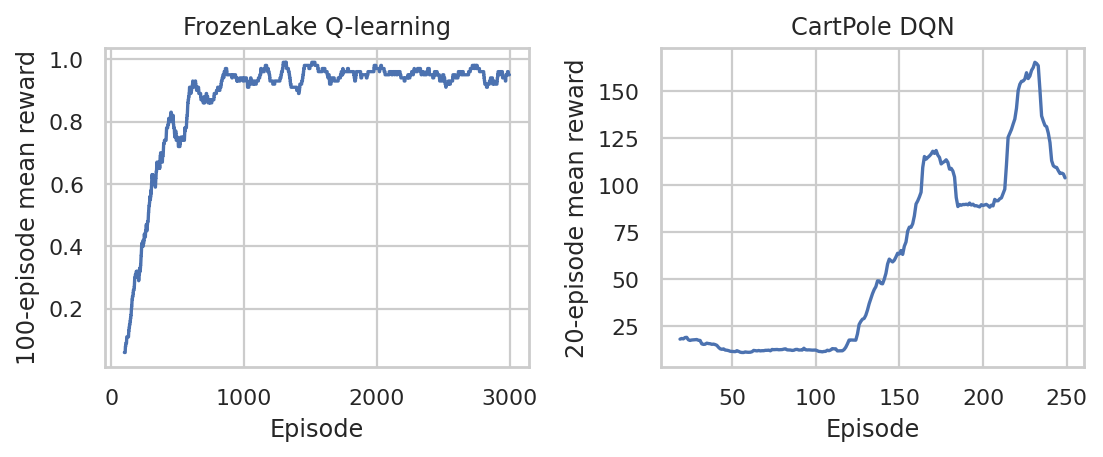

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].plot(pd.Series(frozen["rewards"]).rolling(100).mean())
axes[0].set_title("FrozenLake Q-learning")
axes[0].set_ylabel("100-episode mean reward")
axes[1].plot(pd.Series(dqn_result["rewards"]).rolling(20).mean())
axes[1].set_title("CartPole DQN")
axes[1].set_ylabel("20-episode mean reward")
for axis in axes:
    axis.set_xlabel("Episode")
save_plot("32_learning_curves")


**Observation:** These panels use different tasks and reward scales; their heights should not be compared as algorithm quality.

## Program 33: Compare training time and convergence of Q-Learning and DQN.

**Procedure:** Compare measured CPU training time, environment steps, and late-episode rewards on CartPole.

In [34]:
timing = pd.DataFrame({
    "algorithm": ["Binned Q-learning", "DQN"],
    "seconds": [cart_seconds, dqn_result["seconds"]],
    "training_steps": [cart_steps, dqn_result["steps"]],
    "last20_mean": [np.mean(cart_rewards[-20:]),
                    dqn_result["rewards"][-20:].mean()]})
timing["steps_per_second"] = timing["training_steps"] / timing["seconds"]
print(timing)
print("Timing includes interaction and training, excludes evaluation.")


           algorithm  seconds  training_steps  last20_mean  steps_per_second
0  Binned Q-learning    0.544           16769       81.250         30821.585
1                DQN    3.460           14644      103.900          4232.359
Timing includes interaction and training, excludes evaluation.


**Observation:** CPU time depends on hardware and the actual number of steps. Late rewards indicate progress but do not prove convergence.

## Program 34: Analyze the impact of hyperparameters on learning performance.

**Procedure:** Compare three DQN learning rates with equal episode budgets and two seeds, reusing the measured baseline.

In [35]:
lr_rows = []
for rate in [0.0005, 0.002]:
    for seed in [42, 43]:
        run = train_dqn(episodes=250, seed=seed, learning_rate=rate)
        scores = evaluate_dqn(run["model"])
        lr_rows.append({"learning_rate": rate, "seed": seed,
                        "eval_mean": scores.mean()})
# The default-rate runs already exist in the ablation baseline.
for row in ablations:
    if row["setting"] == "Replay + target":
        lr_rows.append({"learning_rate": 0.001, "seed": row["seed"],
                        "eval_mean": row["eval_mean"]})
lr_table = pd.DataFrame(lr_rows).sort_values(["learning_rate", "seed"])
print("DQN learning-rate results (250 episodes):")
with pd.option_context("display.float_format", lambda x: f"{x:.4f}"):
    print(lr_table)
    print("Mean by rate:")
    print(lr_table.groupby("learning_rate")["eval_mean"].agg(["mean", "std"]))


DQN learning-rate results (250 episodes):
   learning_rate  seed  eval_mean
0         0.0005    42     9.4500
1         0.0005    43     9.4500
4         0.0010    42   107.0000
5         0.0010    43     9.4500
2         0.0020    42   500.0000
3         0.0020    43    98.1000
Mean by rate:
                  mean      std
learning_rate                  
0.0005          9.4500   0.0000
0.0010         58.2250  68.9783
0.0020        299.0500 284.1862


**Observation:** Learning rate changes optimization, while alpha, gamma, and epsilon affect tabular learning. These short two-seed DQN runs are exploratory.

## Program 35: Prepare a comparative report summarizing the performance of Reinforcement Learning algorithms.

**Procedure:** Collect the measured results, document the environments and limitations, and save comparison tables.

In [36]:
report = pd.DataFrame({
    "algorithm": ["Q-learning", "Q-learning", "Binned Q-learning", "DQN"],
    "environment": ["FrozenLake", "Grid World", "CartPole", "CartPole"],
    "training_episodes": [3000, 2000, 250, 250],
    "eval_mean_return": [frozen_eval.mean(), grid_eval.mean(),
                         cart_eval.mean(), dqn_eval.mean()]})
print(report)
print("FrozenLake: non-slippery; reward 1 only at the goal.")
print("Grid World: goal reward 1 and a -0.01 step penalty.")
print("CartPole: reward 1 per step, maximum 500 steps.")
print("Tabular Q stores values; DQN approximates values with a network.")
print("The two CartPole runs use matching evaluation seeds.")
print("Use more training seeds before claiming one method is better.")
report.to_csv(OUT / "rl_comparison.csv", index=False)
ablation_table.to_csv(OUT / "dqn_ablations.csv", index=False)
lr_table.to_csv(OUT / "dqn_learning_rates.csv", index=False)
env.close()
grid.close()


           algorithm environment  training_episodes  eval_mean_return
0         Q-learning  FrozenLake               3000             1.000
1         Q-learning  Grid World               2000             0.950
2  Binned Q-learning    CartPole                250           114.800
3                DQN    CartPole                250           107.000
FrozenLake: non-slippery; reward 1 only at the goal.
Grid World: goal reward 1 and a -0.01 step penalty.
CartPole: reward 1 per step, maximum 500 steps.
Tabular Q stores values; DQN approximates values with a network.
The two CartPole runs use matching evaluation seeds.
Use more training seeds before claiming one method is better.


**Observation:** The report keeps reward definitions explicit and avoids ranking methods across different tasks. Longer, multi-seed experiments would support stronger conclusions.